# LeetCode #1286: Iterator for Combination

https://leetcode.com/problems/iterator-for-combination/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (precompute all)** | $O(C(n,k))$ init, $O(1)$ next | $O(C(n,k) \cdot k)$ |
| **Optimal: On-Demand Backtracking ★** | $O(k)$ per next() call | $O(k)$ |

---

## Understanding the Methods

### Brute Force (precompute all)
Generate all combinations up front during construction and store them in a list. `next()` simply pops from the list. Construction is $O(C(n,k))$ time and space — wasteful if only a few combinations are ever consumed.

### Optimal: On-Demand Backtracking ★
Store a `combinationLength`-size index array representing the current combination as positions in the character string. `next()` advances the indices by one step (incrementing the rightmost index that still has room, then resetting all indices to the right), returning only the current combination string. Space stays $O(k)$ regardless of how many combinations exist, and each call is $O(k)$.

**Constraints:**
* 1 <= combinationLength <= characters.length <= 15
* There will be at most 10^4 calls to next and hasNext.

## Solutions
### C#

In [ ]:
// On-Demand Backtracking: maintain index array representing current combination
public class CombinationIterator {
    private readonly string chars;
    private readonly int k;
    private readonly int[] idx;   // idx[i] = position in chars for the i-th slot
    private bool hasMore;

    public CombinationIterator(string characters, int combinationLength) {
        chars = characters; // already sorted in ascending order
        k = combinationLength;
        idx = new int[k];
        // Initialise to the first combination: [0, 1, 2, ..., k-1]
        for (int i = 0; i < k; i++) idx[i] = i;
        hasMore = true;
    }

    public string Next() {
        // Build the combination string from current indices
        var sb = new System.Text.StringBuilder(k);
        foreach (int i in idx) sb.Append(chars[i]);
        string result = sb.ToString();

        // Advance indices to the next combination in lexicographic order
        Advance();
        return result;
    }

    private void Advance() {
        int n = chars.Length;
        // Find the rightmost index that can still be incremented
        int pos = k - 1;
        while (pos >= 0 && idx[pos] == n - k + pos) pos--;
        if (pos < 0) { hasMore = false; return; }
        // Increment that index and reset all indices to its right
        idx[pos]++;
        for (int i = pos + 1; i < k; i++) idx[i] = idx[i - 1] + 1;
    }

    public bool HasNext() => hasMore;
}

### Python

In [ ]:
# On-Demand Backtracking: maintain index array representing current combination
class CombinationIterator:
    def __init__(self, characters: str, combinationLength: int):
        self.chars = characters  # already sorted ascending
        self.k = combinationLength
        n = len(characters)
        # Start with the lexicographically smallest combination
        self.idx = list(range(combinationLength))
        self.has_more = True

    def next(self) -> str:
        # Build current combination from indices
        result = ''.join(self.chars[i] for i in self.idx)
        self._advance()
        return result

    def _advance(self):
        n = len(self.chars)
        k = self.k
        # Find rightmost index that has room to increment
        pos = k - 1
        while pos >= 0 and self.idx[pos] == n - k + pos:
            pos -= 1
        if pos < 0:
            self.has_more = False
            return
        # Move that index forward and reset all positions to its right
        self.idx[pos] += 1
        for i in range(pos + 1, k):
            self.idx[i] = self.idx[i - 1] + 1

    def hasNext(self) -> bool:
        return self.has_more

### Go

In [ ]:
// On-Demand Backtracking: maintain index array representing current combination
type CombinationIterator struct {
    chars   string
    k       int
    idx     []int
    hasMore bool
}

func Constructor(characters string, combinationLength int) CombinationIterator {
    n := len(characters)
    idx := make([]int, combinationLength)
    // First combination: [0, 1, ..., k-1]
    for i := range idx {
        idx[i] = i
    }
    _ = n
    return CombinationIterator{chars: characters, k: combinationLength, idx: idx, hasMore: true}
}

func (it *CombinationIterator) Next() string {
    // Build combination string from current indices
    buf := make([]byte, it.k)
    for i, pos := range it.idx {
        buf[i] = it.chars[pos]
    }
    result := string(buf)
    it.advance()
    return result
}

func (it *CombinationIterator) advance() {
    n := len(it.chars)
    k := it.k
    // Find rightmost index that can still move forward
    pos := k - 1
    for pos >= 0 && it.idx[pos] == n-k+pos {
        pos--
    }
    if pos < 0 {
        it.hasMore = false
        return
    }
    // Increment that slot and close-pack all slots to its right
    it.idx[pos]++
    for i := pos + 1; i < k; i++ {
        it.idx[i] = it.idx[i-1] + 1
    }
}

func (it *CombinationIterator) HasNext() bool {
    return it.hasMore
}

### Rust

In [ ]:
// On-Demand Backtracking: maintain index array representing current combination
struct CombinationIterator {
    chars: Vec<char>,
    k: usize,
    idx: Vec<usize>,
    has_more: bool,
}

impl CombinationIterator {
    fn new(characters: String, combination_length: i32) -> Self {
        let k = combination_length as usize;
        // First combination: positions [0, 1, ..., k-1]
        let idx: Vec<usize> = (0..k).collect();
        CombinationIterator {
            chars: characters.chars().collect(),
            k,
            idx,
            has_more: true,
        }
    }

    fn next(&mut self) -> String {
        // Build combination string from current index positions
        let result: String = self.idx.iter().map(|&i| self.chars[i]).collect();
        self.advance();
        result
    }

    fn advance(&mut self) {
        let n = self.chars.len();
        let k = self.k;
        // Find rightmost index that has room to increment
        let mut pos = k as isize - 1;
        while pos >= 0 && self.idx[pos as usize] == n - k + pos as usize {
            pos -= 1;
        }
        if pos < 0 {
            self.has_more = false;
            return;
        }
        // Move that index forward and reset all to its right consecutively
        let p = pos as usize;
        self.idx[p] += 1;
        for i in (p + 1)..k {
            self.idx[i] = self.idx[i - 1] + 1;
        }
    }

    fn has_next(&self) -> bool {
        self.has_more
    }
}

## Example Scenarios

The iterator never materialises the combinations. It keeps a $k$-element **index array** into the sorted character string, always in strictly increasing order. `next()` reads off the current indices, then advances: find the rightmost position $p$ with $\text{idx}[p] < n - k + p$ (room to grow), increment it, and repack everything to its right as $\text{idx}[p]+1, \text{idx}[p]+2, \ldots$ That repack is what makes the walk lexicographic.

### 1. Common Case — Two Characters from Three

**Input:** `characters = "abc"`, `combinationLength = 2`

$C(3,2) = 3$ combinations. The index array walks $[0,1] \to [0,2] \to [1,2]$, yielding `"ab"`, `"ac"`, `"bc"`. After $[1,2]$ no position has room — $\text{idx}[1] = 2 = n-k+1$ and $\text{idx}[0] = 1 = n-k+0$ — so `hasNext()` turns false. Each call is $O(k)$.

### 2. Slightly Complex — Three Characters from Four

**Input:** `characters = "abcd"`, `combinationLength = 3`

$C(4,3) = 4$: `"abc"`, `"abd"`, `"acd"`, `"bcd"`. Watch the carry. From $[0,1,2]$ the last position still has room ($2 < 4-3+2 = 3$), so it simply increments to $[0,1,3]$ = `"abd"`. Only *then* is the last position stuck, so the carry moves left to position 1, giving $[0,2,3]$ = `"acd"`. The repack rule — rather than a plain increment — is what turns $[0,2,\cdot]$ into $[0,2,3]$ instead of an invalid $[0,2,2]$.

### 3. Edge Case: Time Factor — Length Equals the Whole String

**Input:** `characters = "abcde"`, `combinationLength = 5`

Exactly one combination exists. The first `next()` returns `"abcde"`, and the advance scan then walks all 5 positions, finds every one already at its ceiling $n-k+p = p$, falls off the left end, and sets `hasNext()` false. This is the most expensive *single* advance relative to its yield: $O(k)$ work to discover there is nothing left.

### 4. Edge Case: Space Factor — Maximum Alphabet, Minimum Length

**Input:** `characters = "abcdefghijklmno"`, `combinationLength = 1`

15 single-character combinations, and the index array has exactly one slot for all of them. The whole iterator is one integer plus a flag — no list of results is ever built. Contrast the precompute approach, which would allocate all 15 strings up front even if the caller stops after the first.

### 5. Almost-Impossible but Plausible — Maximum Parameters, Maximum Calls

**Input:** `characters = "abcdefghijklmno"`, `combinationLength = 7`

$C(15,7) = 6435$ combinations, from `"abcdefg"` to `"ijklmno"`, and the problem allows up to $10^4$ calls — enough to exhaust the iterator and then keep asking. Total work is $6435 \times O(7) \approx 45\,000$ character operations, generated lazily. Precomputing instead would hold $6435 \times 7 = 45\,045$ characters in memory *before the first call returns*, which is the entire point of the on-demand design.


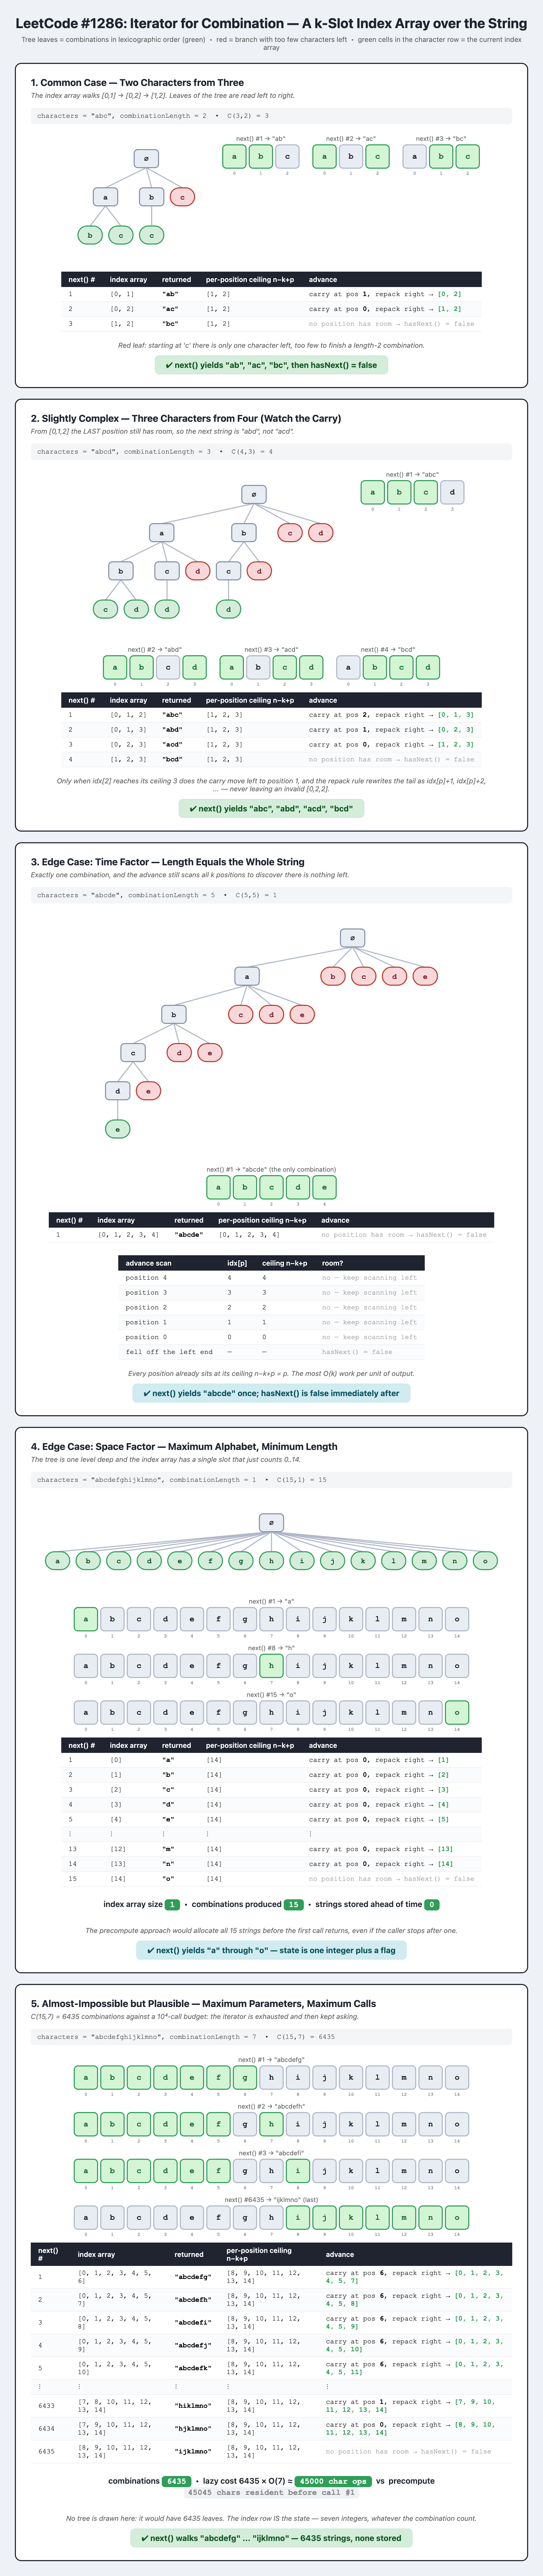